In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)


3.13.15 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3265
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)


(4204, 57) 39.9 (3153, 57) (1051, 57)


# Task 4 - Random Forests & Ensembles

Surname: Bissenbai  
Student ID (last four digits): 3265  
SEED = 3265

I use the same train/test split and five folds in all parts.
Spam is class 1. Legitimate email is class 0.
A false positive is a legitimate email marked as spam.
I use the training data to make choices and the test data to check the results.


In [3]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]


## Part 1 - Bagging and out-of-bag estimates


In [4]:
def oob_mask(sample_indices, n_samples):
    """Return True for rows that are absent from a bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    indices = np.asarray(sample_indices, dtype=int)
    mask[indices] = False
    return mask


### Checking the function

Repeated indices still mark the same row as in-bag. An empty sample leaves every row out of bag.


In [5]:
assert np.array_equal(oob_mask([0, 2, 2], 5), [False, True, False, True, True])
assert np.array_equal(oob_mask([], 3), [True, True, True])
assert np.array_equal(oob_mask(np.array([3, 0]), 4), [False, True, True, False])

sample = np.array([3, 0, 3])
original_sample = sample.copy()
result = oob_mask(sample_indices=sample, n_samples=4)
assert np.array_equal(sample, original_sample)
assert result.dtype == np.dtype(bool) and result.shape == (4,)
assert oob_mask([], 0).shape == (0,)
print("All oob_mask checks passed.")


All oob_mask checks passed.


### 1. Out-of-bag share

Each tree draws as many rows as the training set contains, with replacement.
Some rows are repeated, so the tree does not see every training row.
For a particular row, the probability of being left out is $(1 - 1/n)^n$.


In [6]:
bag.fit(X_train, y_train)

n_train = len(y_train)
oob_masks = [oob_mask(indices, n_train) for indices in bag.estimators_samples_]
oob_shares = np.array([mask.mean() for mask in oob_masks])
expected_oob = (1 - 1 / n_train) ** n_train

share_table = pd.DataFrame({
    "Observed mean": [oob_shares.mean(), 1 - oob_shares.mean()],
    "Formula": [expected_oob, 1 - expected_oob],
}, index=["Out of bag", "In bag (unique rows)"])
share_table.round(6)


,Observed mean,Formula
Out of bag,0.367796,0.367821
In bag (unique rows),0.632204,0.632179


### 2. Out-of-bag accuracy by hand

For each row, I count votes only from trees that did not train on that row.
The larger count gives the predicted class. With argmax, a tie gives class 0.


In [7]:
oob_votes = np.zeros((n_train, 2), dtype=int)

for estimator, mask in zip(bag.estimators_, oob_masks):
    row_indices = np.flatnonzero(mask)
    predictions = estimator.predict(X_train[mask]).astype(int)
    oob_votes[row_indices, predictions] += 1

print("Rows with no OOB votes:", np.sum(oob_votes.sum(axis=1) == 0))
assert np.all(oob_votes.sum(axis=1) > 0)

oob_predictions = np.argmax(oob_votes, axis=1)
manual_oob_accuracy = np.mean(oob_predictions == y_train)
print(f"Manual OOB accuracy:       {manual_oob_accuracy:.6f}")
print(f"BaggingClassifier OOB:     {bag.oob_score_:.6f}")
print(f"Absolute difference:       {abs(manual_oob_accuracy - bag.oob_score_):.12f}")
assert np.isclose(manual_oob_accuracy, bag.oob_score_)


Rows with no OOB votes: 0
Manual OOB accuracy:       0.933080
BaggingClassifier OOB:     0.933080
Absolute difference:       0.000000000000


### 3. Five models on the same folds

I compare accuracy on the five training folds. cross_validate makes a fresh copy of the model for each fold.
The transformations for logistic regression stay inside its pipeline, so the scaler only sees the training rows of each fold.
The standard deviation uses ddof=0, as required.


In [8]:
from sklearn.model_selection import cross_validate

models_part1 = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
cv_scores = {}
cv_rows = []

for name, model in models_part1.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    cv_scores[name] = scores
    cv_rows.append([name, *scores, scores.mean(), scores.std()])

score_columns = ["Model", "Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5", "Mean", "Std"]
cv_table_part1 = pd.DataFrame(cv_rows, columns=score_columns).set_index("Model")
cv_table_part1.round(6)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Model,,,,,,,
tree,0.889065,0.885895,0.881141,0.906349,0.907937,0.894077,0.010974
bag,0.923930,0.923930,0.923930,0.942857,0.949206,0.932771,0.011012
rf,0.935024,0.942948,0.939778,0.944444,0.955556,0.943550,0.006815
lr,0.928685,0.936609,0.920761,0.928571,0.947619,0.932449,0.009091
bag_lr,0.930269,0.938193,0.920761,0.928571,0.947619,0.933083,0.009138


In [9]:
paired_differences_part1 = {}
difference_rows = []

for first, second in [("bag", "tree"), ("rf", "tree"), ("bag_lr", "lr")]:
    name = f"{first} - {second}"
    differences = cv_scores[first] - cv_scores[second]
    paired_differences_part1[name] = differences
    difference_rows.append([
        name, *differences, differences.mean(), differences.std(),
        abs(differences.mean()) <= differences.std(),
    ])

difference_columns = ["Comparison", "Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5",
                      "Mean", "Std", "Inside fold spread"]
paired_table_part1 = pd.DataFrame(difference_rows, columns=difference_columns).set_index("Comparison")
paired_table_part1.round(6)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std,Inside fold spread
Comparison,,,,,,,,
bag - tree,0.034865,0.038035,0.042789,0.036508,0.041270,0.038693,0.002942,False
rf - tree,0.045959,0.057052,0.058637,0.038095,0.047619,0.049472,0.007572,False
bag_lr - lr,0.001585,0.001585,0.000000,0.000000,0.000000,0.000634,0.000776,True


### 4. One forest, three estimates

I fit the fixed random forest on the full training set and keep it for the next part.
The test standard error is $\sqrt{p(1-p)/n_{test}}$, where $p$ is its test accuracy.


In [10]:
rf.fit(X_train, y_train)

rf_cv_mean = cv_scores["rf"].mean()
rf_cv_std = cv_scores["rf"].std()
rf_test_accuracy = rf.score(X_test, y_test)
rf_test_se = np.sqrt(rf_test_accuracy * (1 - rf_test_accuracy) / len(y_test))

forest_estimates = pd.DataFrame({
    "Estimate": ["OOB accuracy", "CV mean accuracy", "Test accuracy"],
    "Accuracy": [rf.oob_score_, rf_cv_mean, rf_test_accuracy],
}).set_index("Estimate")
display(forest_estimates.round(6))
print(f"CV standard deviation: {rf_cv_std:.6f}")
print(f"Test standard error:   {rf_test_se:.6f}")
print(f"OOB-CV absolute gap:   {abs(rf.oob_score_ - rf_cv_mean):.6f}")
print("OOB and CV agree by the task rule:", abs(rf.oob_score_ - rf_cv_mean) <= rf_cv_std)
print(f"OOB-test absolute gap: {abs(rf.oob_score_ - rf_test_accuracy):.6f}")
print(f"CV-test absolute gap:  {abs(rf_cv_mean - rf_test_accuracy):.6f}")


,Accuracy
Estimate,
OOB accuracy,0.944497
CV mean accuracy,0.943550
Test accuracy,0.957184


CV standard deviation: 0.006815
Test standard error:   0.006245
OOB-CV absolute gap:   0.000947
OOB and CV agree by the task rule: True
OOB-test absolute gap: 0.012686
CV-test absolute gap:  0.013634


### What the results show

**Bootstrap and OOB.** The mean OOB share is 0.367796, close to the formula value of 0.367821. This means that each tree leaves out about 36.8% of the training rows. The manual OOB accuracy matches bag.oob_score_, and every training row has at least one OOB vote.

**Bagging trees.** Mean CV accuracy increases from 0.894077 for one tree to 0.932771 for bagging. The paired improvement is 0.038693 with a standard deviation of 0.002942. It is outside the fold spread, so bagging helps the tree here. A single unrestricted tree can change a lot when its training sample changes; combining bootstrap trees reduces this variance.

**Random forest versus one tree.** The forest's mean CV accuracy is 0.943550. Its paired improvement over the tree is 0.049472 with a standard deviation of 0.007572, also outside the fold spread. In addition to bootstrap sampling, the forest considers a random subset of features at each split, which makes the trees less similar.

**Bagging logistic regression.** The mean accuracy changes from 0.932449 to 0.933083. The paired improvement is only 0.000634, smaller than its standard deviation of 0.000776. This is inside the fold spread, so these results do not support choosing bagged logistic regression over the single model. Logistic regression is usually more stable than an unrestricted tree, so averaging bootstrap fits has less variance to reduce.

**The forest's three estimates.** OOB accuracy is 0.944497 and mean CV accuracy is 0.943550. Their gap of 0.000947 is below the CV standard deviation of 0.006815, so OOB is a fair stand-in for CV by the task's rule. Test accuracy is 0.957184 with a standard error of 0.006245. The test result is higher than OOB by 0.012686 and higher than CV by 0.013634; both gaps exceed one test standard error. OOB and CV therefore agree with each other, but are somewhat lower than this test result. The test standard error describes uncertainty in the test accuracy alone; it is not a formal test of the difference between these estimates.


## Part 2 - Evaluating the filter

The goal is to flag no more than 1% of legitimate emails as spam.
I compare the tree and forest, then choose a threshold for the forest.


### 1. ROC and precision-recall curves

I fit a fresh copy of the tree. The forest is already fitted on the training data in Part 1.
Both curves use spam probabilities for the same test rows.


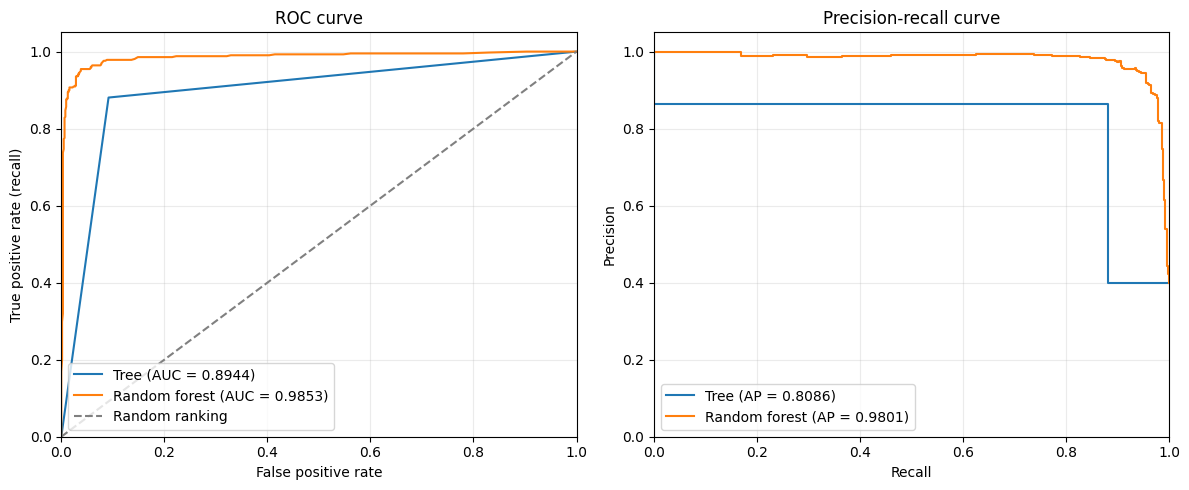

,ROC AUC,Average precision
Model,,
Tree,0.894448,0.808620
Random forest,0.985320,0.980053


In [11]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score, confusion_matrix, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)

tree_fitted = clone(tree).fit(X_train, y_train)
tree_test_prob = tree_fitted.predict_proba(X_test)[:, 1]
rf_test_prob = rf.predict_proba(X_test)[:, 1]

test_probabilities = {"Tree": tree_test_prob, "Random forest": rf_test_prob}
curve_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    curve_rows.append([name, auc, ap])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
    axes[1].step(recall, precision, where="post", label=f"{name} (AP = {ap:.4f})")

axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[0].set_title("ROC curve")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[1].set_title("Precision-recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(loc="lower left")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()
curve_table = pd.DataFrame(curve_rows, columns=["Model", "ROC AUC", "Average precision"])
curve_table.set_index("Model").round(6)


### 2. Choosing the threshold

Each training row gets a probability from a forest that did not train on that row.
I keep thresholds with an out-of-fold FPR of at most 0.01 and choose the highest recall.
If several thresholds have that recall, I take the largest threshold.


In [12]:
from sklearn.model_selection import cross_val_predict

rf_oof_prob = cross_val_predict(
    rf, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

oof_fpr, oof_recall, oof_thresholds = roc_curve(
    y_train, rf_oof_prob, drop_intermediate=False
)
valid_indices = np.flatnonzero(oof_fpr <= 0.01)
best_recall = oof_recall[valid_indices].max()
best_indices = valid_indices[oof_recall[valid_indices] == best_recall]
best_index = best_indices[np.argmax(oof_thresholds[best_indices])]
rf_threshold = oof_thresholds[best_index]

print("Chosen threshold:", rf_threshold)
print(f"Out-of-fold FPR:    {oof_fpr[best_index]:.6f}")
print(f"Out-of-fold recall: {oof_recall[best_index]:.6f}")


Chosen threshold: 0.7366666666666667
Out-of-fold FPR:    0.009494
Out-of-fold recall: 0.813047


### 3. Applying the threshold to the test set

An email is marked as spam when its probability is greater than or equal to the threshold.
I use the full threshold value from the previous cell and do not change it after this check.


In [13]:
rf_test_labels = (rf_test_prob >= rf_threshold).astype(int)
test_cm = confusion_matrix(y_test, rf_test_labels, labels=[0, 1])
tn, fp, fn, tp = test_cm.ravel()

confusion_table = pd.DataFrame(
    test_cm,
    index=["Actual legitimate (0)", "Actual spam (1)"],
    columns=["Predicted legitimate (0)", "Predicted spam (1)"],
)
display(confusion_table)

rf_threshold_precision = precision_score(y_test, rf_test_labels, zero_division=0)
rf_threshold_recall = recall_score(y_test, rf_test_labels)
rf_threshold_fpr = fp / (tn + fp)

print(f"Test precision: {rf_threshold_precision:.6f}")
print(f"Test recall:    {rf_threshold_recall:.6f}")
print(f"Test FPR:       {rf_threshold_fpr:.6f} ({100 * rf_threshold_fpr:.2f}%)")
print(f"Legitimate test emails flagged as spam: {fp} out of {tn + fp}.")
print("The 1% target held on the test set:", rf_threshold_fpr <= 0.01)


,Predicted legitimate (0),Predicted spam (1)
Actual legitimate (0),628,4
Actual spam (1),75,344


Test precision: 0.988506
Test recall:    0.821002
Test FPR:       0.006329 (0.63%)
Legitimate test emails flagged as spam: 4 out of 632.
The 1% target held on the test set: True


### 4. Feature importance

Impurity importance measures how much a feature helps split the training data in the trees.
Permutation importance measures the drop in test accuracy when one feature is shuffled.
I use these results to explain the forest, not to change the model or threshold.


In [14]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy"
)

importance_table = pd.DataFrame({
    "Feature": feature_names,
    "Permutation importance": perm.importances_mean,
    "Impurity importance": rf.feature_importances_,
})

top_permutation = importance_table.sort_values("Permutation importance", ascending=False).head(5)
top_impurity = importance_table.sort_values("Impurity importance", ascending=False).head(5)

print("Top five features by permutation importance")
display(top_permutation[["Feature", "Permutation importance"]].set_index("Feature").round(6))
print("Top five features by impurity importance")
display(top_impurity[["Feature", "Impurity importance"]].set_index("Feature").round(6))


Top five features by permutation importance


,Permutation importance
Feature,
word_freq_remove,0.022835
word_freq_hp,0.017697
char_freq_exclam,0.013035
char_freq_dollar,0.009515
capital_run_length_average,0.008849


Top five features by impurity importance


,Impurity importance
Feature,
char_freq_exclam,0.124179
char_freq_dollar,0.092188
word_freq_remove,0.080665
capital_run_length_average,0.067148
word_freq_free,0.063657


### What the results show

On this test set, the forest has a higher ROC AUC (0.985320) and average precision (0.980053) than the tree (0.894448 and 0.808620).

The chosen threshold is 0.7366666666666667. On the training folds, its FPR is 0.9494% and recall is 81.30%. On the test set, precision is 98.85%, recall is 82.10%, and FPR is 0.63%. It flags 4 out of 632 legitimate emails, so the 1% target holds. It catches 344 spam emails and misses 75. I keep the same threshold after checking these results.

word_freq_remove is first by permutation importance but third by impurity importance. Shuffling it lowers test accuracy by about 0.022835, or 2.28 percentage points. Impurity importance adds up improvements from training splits. Permutation importance checks how much the fitted model needs the feature on the test set. These measure different things, so their rankings can differ.


## Part 3 - Voting


In [15]:
def hard_vote(predictions, weights=None):
    """Return the label with the most weight for each sample; ties go to the smaller label."""
    predictions = np.asarray(predictions, dtype=int)
    n_models, n_samples = predictions.shape
    if weights is None:
        weights = np.ones(n_models)
    else:
        weights = np.asarray(weights, dtype=float)

    result = np.zeros(n_samples, dtype=int)
    for sample in range(n_samples):
        largest_label = predictions[:, sample].max(initial=0)
        counts = np.zeros(largest_label + 1)
        for model in range(n_models):
            label = predictions[model, sample]
            counts[label] += weights[model]
        result[sample] = np.argmax(counts)
    return result


### Checking the function

I add weights in model order. The label with the largest total wins.
With equal totals, argmax takes the smaller label.
If all weights are zero, the result is class 0.


In [16]:
assert np.array_equal(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]), [0, 1, 0])
assert np.array_equal(hard_vote([[0, 1], [1, 0]]), [0, 0])
assert np.array_equal(hard_vote([[0, 1], [1, 0]], weights=[1, 2]), [1, 0])
assert np.array_equal(hard_vote([[2, 0], [2, 1], [0, 1]]), [2, 1])
assert np.array_equal(hard_vote([[2, 3], [4, 5]], weights=[0, 0]), [0, 0])
assert np.array_equal(hard_vote([[7], [3]]), [3])

# A tiny difference is still a difference, not a tie.
assert np.array_equal(hard_vote([[0], [1]], weights=[1.0, np.nextafter(1.0, 2.0)]), [1])

predictions_check = np.array([[0, 1], [1, 0]])
weights_check = np.array([0.5, 1.0])
predictions_before = predictions_check.copy()
weights_before = weights_check.copy()
result_check = hard_vote(predictions=predictions_check, weights=weights_check)
assert np.array_equal(predictions_check, predictions_before)
assert np.array_equal(weights_check, weights_before)
assert result_check.shape == (2,) and np.issubdtype(result_check.dtype, np.integer)
assert hard_vote([[], []]).shape == (0,)
print("All hard_vote checks passed.")


All hard_vote checks passed.


### 1. Comparing with sklearn

I fit fresh copies of logistic regression, KNN and the tree on the training set.
Their test labels form a matrix with three rows, one per model.
I compare my vote with VotingClassifier using the same models.


In [17]:
from sklearn.ensemble import VotingClassifier

member_predictions = {}
for name, member in members:
    fitted_member = clone(member).fit(X_train, y_train)
    member_predictions[name] = fitted_member.predict(X_test)

prediction_matrix = np.vstack([member_predictions[name] for name, _ in members])
manual_hard_predictions = hard_vote(prediction_matrix)

hard_voting = VotingClassifier(members, voting="hard").fit(X_train, y_train)
sklearn_hard_predictions = hard_voting.predict(X_test)
agreement = np.mean(manual_hard_predictions == sklearn_hard_predictions)

print("Prediction matrix shape:", prediction_matrix.shape)
print(f"Agreement with sklearn: {agreement:.6f} ({agreement * 100:.2f}%)")


Prediction matrix shape: (3, 1051)
Agreement with sklearn: 1.000000 (100.00%)


/Users/macz/Documents/Codex/2026-11-15/new-chat/task-04-ML-course/.bissenbai_ML_task_4/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/macz/Documents/Codex/2026-11-15/new-chat/task-04-ML-course/.bissenbai_ML_task_4/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py", line 249, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/Users/macz/Documents/Codex/2026-11-15/new-chat/task-04-ML-course/.bissenbai_ML_task_4/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py", line 318, in _count_physical_cores_darwin
    return int(cpu_info)


### 2. Disagreement between members

For each pair, I count the test rows where their predicted labels differ.
The fraction shows how often the models disagree.


In [18]:
disagreement_rows = []
for first, second in [("lr", "knn"), ("lr", "tree"), ("knn", "tree")]:
    disagreement = np.mean(member_predictions[first] != member_predictions[second])
    disagreement_rows.append([f"{first} / {second}", disagreement])

disagreement_table = pd.DataFrame(disagreement_rows, columns=["Pair", "Disagreement"])
disagreement_table.set_index("Pair").round(6)


,Disagreement
Pair,
lr / knn,0.050428
lr / tree,0.108468
knn / tree,0.118934


### 3. Cross-validation

Hard voting uses predicted labels. Soft voting averages the spam probabilities.
I compare both methods and the three members on the same five training folds.
The best member is the one with the highest mean CV accuracy.


In [19]:
soft_voting = VotingClassifier(members, voting="soft")
models_part3 = {
    "lr": lr,
    "knn": knn,
    "tree": tree,
    "hard voting": hard_voting,
    "soft voting": soft_voting,
}
voting_cv_scores = {}
voting_cv_rows = []

for name, model in models_part3.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    voting_cv_scores[name] = scores
    voting_cv_rows.append([name, *scores, scores.mean(), scores.std()])

voting_cv_table = pd.DataFrame(voting_cv_rows, columns=score_columns).set_index("Model")
display(voting_cv_table.round(6))

best_member_name = max([name for name, _ in members], key=lambda name: voting_cv_scores[name].mean())
best_member = dict(members)[best_member_name]
print("Best member by mean CV accuracy:", best_member_name)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Model,,,,,,,
lr,0.928685,0.936609,0.920761,0.928571,0.947619,0.932449,0.009091
knn,0.920761,0.919176,0.916006,0.912698,0.931746,0.920077,0.006457
tree,0.889065,0.885895,0.881141,0.906349,0.907937,0.894077,0.010974
hard voting,0.931854,0.935024,0.922345,0.930159,0.947619,0.933400,0.008245
soft voting,0.933439,0.927100,0.925515,0.933333,0.947619,0.933401,0.007798


Best member by mean CV accuracy: lr


In [20]:
voting_difference_rows = []
voting_differences = {}

for name in ["hard voting", "soft voting"]:
    differences = voting_cv_scores[name] - voting_cv_scores[best_member_name]
    voting_differences[name] = differences
    voting_difference_rows.append([
        f"{name} - {best_member_name}", *differences, differences.mean(), differences.std(),
        abs(differences.mean()) <= differences.std(),
    ])

voting_difference_table = pd.DataFrame(
    voting_difference_rows, columns=difference_columns
).set_index("Comparison")
voting_difference_table.round(6)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std,Inside fold spread
Comparison,,,,,,,,
hard voting - lr,0.003170,-0.001585,0.001585,0.001587,0.0,0.000951,0.001616,True
soft voting - lr,0.004754,-0.009509,0.004754,0.004762,0.0,0.000952,0.005546,True


### What the results show

My hard_vote gives the same labels as sklearn on all 1051 test rows. KNN and the tree disagree most often (11.89%), while logistic regression and KNN disagree least often (5.04%). Different predictions can help an ensemble, but they do not guarantee better accuracy.

Logistic regression is the best member, with mean CV accuracy of 0.932449. Hard voting reaches 0.933400. Its mean paired gain is 0.000951, below the standard deviation of 0.001616. This is inside the fold spread, so hard voting does not show a clear win over logistic regression.

Soft voting reaches mean CV accuracy of 0.933401. Its mean paired gain over logistic regression is 0.000952, below the standard deviation of 0.005546. This is also inside the fold spread, so I cannot call soft voting better than the best member either.


## Part 4 - Stacking

Stacking uses another model to combine the members' predictions.
Here, this final model is logistic regression with default settings.


### 1. Out-of-fold stacking by hand

I make three columns of out-of-fold spam probabilities: lr, knn and tree, in that order.
Each training row is predicted by a model that did not train on it.
The final model learns from these columns.
For the test columns, I fit fresh copies of the members on the full training set.


In [21]:
oof_columns = []
test_columns = []

for name, member in members:
    oof_probabilities = cross_val_predict(
        member, X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]
    oof_columns.append(oof_probabilities)

    fitted_member = clone(member).fit(X_train, y_train)
    test_columns.append(fitted_member.predict_proba(X_test)[:, 1])

stack_train = np.column_stack(oof_columns)
stack_test = np.column_stack(test_columns)
meta_oof = LogisticRegression().fit(stack_train, y_train)
manual_stack_predictions = meta_oof.predict(stack_test)
manual_stack_accuracy = np.mean(manual_stack_predictions == y_test)

print("Training matrix shape:", stack_train.shape)
print("Test matrix shape:", stack_test.shape)


Training matrix shape: (3153, 3)
Test matrix shape: (1051, 3)


In [22]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
sklearn_stack_predictions = stack.predict(X_test)
sklearn_stack_accuracy = stack.score(X_test, y_test)
coefficient_gap = np.max(np.abs(meta_oof.coef_ - stack.final_estimator_.coef_))

print(f"Largest coefficient difference: {coefficient_gap:.12g}")
print("Test predictions are identical:", np.array_equal(manual_stack_predictions, sklearn_stack_predictions))
print(f"Manual stacking test accuracy:  {manual_stack_accuracy:.6f}")
print(f"Sklearn stacking test accuracy: {sklearn_stack_accuracy:.6f}")


Largest coefficient difference: 0
Test predictions are identical: True
Manual stacking test accuracy:  0.942912
Sklearn stacking test accuracy: 0.942912


### 2. Naive stacking

Now each member predicts the same training rows it learned from.
I fit a second final model on these probabilities and compare its coefficients with the out-of-fold version.


In [23]:
naive_columns = []
for name, member in members:
    fitted_member = clone(member).fit(X_train, y_train)
    naive_columns.append(fitted_member.predict_proba(X_train)[:, 1])

naive_train = np.column_stack(naive_columns)
meta_naive = LogisticRegression().fit(naive_train, y_train)

coefficient_table = pd.DataFrame({
    "Member": [name for name, _ in members],
    "Naive coefficient": meta_naive.coef_[0],
    "Out-of-fold coefficient": meta_oof.coef_[0],
}).set_index("Member")
coefficient_table.round(6)


,Naive coefficient,Out-of-fold coefficient
Member,,
lr,1.920375,3.498163
knn,1.842608,3.248119
tree,8.298183,1.323341


### 3. Cross-validation

I compare stacking, soft voting and the best member from Part 3 on the same five folds.
Inside each training fold, stacking makes its own five-fold split to train the final model.
The outer validation rows are not used in this training.


In [24]:
stacking_models = {"stack": stack, "soft voting": soft_voting, best_member_name: best_member}
stacking_cv_scores = {}
stacking_cv_rows = []

for name, model in stacking_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    stacking_cv_scores[name] = scores
    stacking_cv_rows.append([name, *scores, scores.mean(), scores.std()])

stacking_cv_table = pd.DataFrame(stacking_cv_rows, columns=score_columns).set_index("Model")
stacking_cv_table.round(6)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Model,,,,,,,
stack,0.933439,0.930269,0.927100,0.930159,0.949206,0.934035,0.007846
soft voting,0.933439,0.927100,0.925515,0.933333,0.947619,0.933401,0.007798
lr,0.928685,0.936609,0.920761,0.928571,0.947619,0.932449,0.009091


In [25]:
stacking_difference_rows = []
stacking_differences = {}

for other in [best_member_name, "soft voting"]:
    differences = stacking_cv_scores["stack"] - stacking_cv_scores[other]
    stacking_differences[other] = differences
    stacking_difference_rows.append([
        f"stack - {other}", *differences, differences.mean(), differences.std(),
        abs(differences.mean()) <= differences.std(),
    ])

stacking_difference_table = pd.DataFrame(
    stacking_difference_rows, columns=difference_columns
).set_index("Comparison")
stacking_difference_table.round(6)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std,Inside fold spread
Comparison,,,,,,,,
stack - lr,0.004754,-0.006339,0.006339,0.001587,0.001587,0.001586,0.004369,True
stack - soft voting,0.000000,0.003170,0.001585,-0.003175,0.001587,0.000633,0.002152,True


### What the results show

My stacking matches sklearn. The largest coefficient difference is 0, the test predictions are identical, and both test accuracies are 0.942912.

The tree's coefficient falls from 8.298183 in naive stacking to 1.323341 in out-of-fold stacking. The tree predicts its own training rows perfectly, so the naive final model gives it a large weight. Out-of-fold predictions come from rows the tree did not train on. They show its mistakes, so the final model relies less on the tree and gives larger coefficients to lr and knn.

Stacking has mean CV accuracy of 0.934035. Its paired gain over logistic regression is 0.001586 with a standard deviation of 0.004369. The gain is inside the fold spread, so I cannot say stacking beats the best member.

Against soft voting, the paired gain is 0.000633 with a standard deviation of 0.002152. This is also inside the fold spread, so the results do not show a clear win over soft voting either.


## Part 5 - AdaBoost and label noise


In [26]:
def adaboost_step(y_true, y_pred, weights):
    """Return alpha and the normalised row weights after one AdaBoost round."""
    import math

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    new_weights = np.asarray(weights, dtype=float).copy()
    wrong = y_pred != y_true
    error = new_weights[wrong].sum() / new_weights.sum()

    if error == 0:
        return math.inf, new_weights / new_weights.sum()

    alpha = math.log((1 - error) / error)
    new_weights[wrong] *= math.exp(alpha)
    new_weights /= new_weights.sum()
    return alpha, new_weights


### Checking the function

The error is the share of weight on wrong predictions.
Wrong rows are multiplied by exp(alpha), then all weights are normalised.
At error 0, alpha is infinite and the weights are only normalised.
At error 0.5 or above, I still use the same formula, even when alpha is zero or negative.


In [27]:
step_examples = [
    ([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1], np.log(3), [1/6, 1/2, 1/6, 1/6]),
    ([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1], -np.log(3), [1/6, 1/6, 1/6, 1/2]),
    ([1, 0], [0, 0], [1, 1], 0.0, [0.5, 0.5]),
    ([1, 0, 1], [1, 0, 1], [2, 2, 4], np.inf, [0.25, 0.25, 0.5]),
    ([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1], np.log(4), [0.125, 0.25, 0.5, 0.125]),
]

for true, predicted, weights, expected_alpha, expected_weights in step_examples:
    alpha, updated = adaboost_step(true, predicted, weights)
    assert isinstance(alpha, float)
    assert updated.shape == (len(true),) and np.issubdtype(updated.dtype, np.floating)
    assert np.isclose(alpha, expected_alpha)
    assert np.allclose(updated, expected_weights)

true_check = np.array([1, 0])
predicted_check = np.array([0, 0])
weights_check = np.array([0.0, 2.0])
true_before = true_check.copy()
predicted_before = predicted_check.copy()
weights_before = weights_check.copy()
alpha, updated = adaboost_step(y_true=true_check, y_pred=predicted_check, weights=weights_check)
assert np.isinf(alpha) and np.array_equal(updated, [0.0, 1.0])
assert np.array_equal(true_check, true_before)
assert np.array_equal(predicted_check, predicted_before)
assert np.array_equal(weights_check, weights_before)
assert not np.shares_memory(updated, weights_check)
print("All adaboost_step checks passed.")


All adaboost_step checks passed.


### 1. The lecture's three rounds

I start with weight 0.1 on each of the ten rows.
Each round uses the weights returned by the previous round.


In [28]:
x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)

toy_weights = np.full(10, 0.1)
toy_errors = []
toy_alphas = []
for round_number, predictions in enumerate([stump_1, stump_2, stump_3], start=1):
    error = toy_weights[predictions != y_toy].sum() / toy_weights.sum()
    alpha, toy_weights = adaboost_step(y_toy, predictions, toy_weights)
    toy_errors.append(error)
    toy_alphas.append(alpha)
    print(f"Round {round_number}: error = {error:.6f}, alpha = {alpha:.6f}")
    print("New weights:", np.round(toy_weights, 6))

# Exact values for this three-stump example.
assert np.allclose(toy_errors, [3/10, 3/14, 2/11])
assert np.allclose(toy_alphas, np.log([7/3, 11/3, 9/2]))


Round 1: error = 0.300000, alpha = 0.847298
New weights: [0.071429 0.071429 0.071429 0.071429 0.071429 0.071429 0.166667 0.166667
 0.166667 0.071429]
Round 2: error = 0.214286, alpha = 1.299283
New weights: [0.045455 0.045455 0.045455 0.166667 0.166667 0.166667 0.106061 0.106061
 0.106061 0.045455]
Round 3: error = 0.181818, alpha = 1.504077
New weights: [0.125    0.125    0.125    0.101852 0.101852 0.101852 0.064815 0.064815
 0.064815 0.125   ]


### 2. Checking sklearn's first five rounds

I fit the fixed 400-round AdaBoost on the training set.
I start from equal row weights and rebuild its first five updates.


In [29]:
ada.fit(X_train, y_train)

check_weights = np.full(len(y_train), 1 / len(y_train))
ada_check_rows = []
for t in range(5):
    predictions = ada.estimators_[t].predict(X_train)
    error = check_weights[predictions != y_train].sum() / check_weights.sum()
    alpha, check_weights = adaboost_step(y_train, predictions, check_weights)
    ada_check_rows.append([
        t + 1, error, ada.estimator_errors_[t], alpha, ada.estimator_weights_[t]
    ])

ada_check_table = pd.DataFrame(ada_check_rows, columns=[
    "Round", "Manual error", "Sklearn error", "Manual alpha", "Sklearn alpha"
]).set_index("Round")
display(ada_check_table.round(9))

alpha_gap = np.max(np.abs(ada_check_table["Manual alpha"] - ada_check_table["Sklearn alpha"]))
error_gap = np.max(np.abs(ada_check_table["Manual error"] - ada_check_table["Sklearn error"]))
print(f"Largest alpha difference: {alpha_gap:.12g}")
print(f"Largest error difference: {error_gap:.12g}")


,Manual error,Sklearn error,Manual alpha,Sklearn alpha
Round,,,,
1,0.217253,0.217253,1.281745,1.281745
2,0.246987,0.246987,1.114746,1.114746
3,0.278839,0.278839,0.950228,0.950228
4,0.262122,0.262122,1.034969,1.034969
5,0.367855,0.367855,0.541431,0.541431


Largest alpha difference: 4.4408920985e-16
Largest error difference: 5.55111512313e-17


### 3. Error by round

I record training and test error after each stump.
These curves describe the fitted model. The test curve is not used to choose the number of rounds.


In [30]:
ada_train_errors = 1 - np.array(list(ada.staged_score(X_train, y_train)))
ada_test_errors = 1 - np.array(list(ada.staged_score(X_test, y_test)))
rounds = np.arange(1, len(ada_train_errors) + 1)
print("Number of rounds in the curves:", len(rounds))


Number of rounds in the curves: 400


### 4. Choosing the number of rounds

For each training fold, I fit a fresh AdaBoost and score every round on that fold's validation rows.
I choose the round with the highest mean validation accuracy.
If several rounds tie, argmax takes the first one.
After choosing it, I compare its test error with the lowest point on the test curve.


Round chosen by training CV: 193
Mean CV accuracy at this round: 0.938471
Test error at the chosen round: 0.057088
First round with the lowest test error: 312
Lowest test error:              0.053283
Difference in test errors:      0.003806
Test accuracy standard error:   0.007157
Difference exceeds one standard error: False


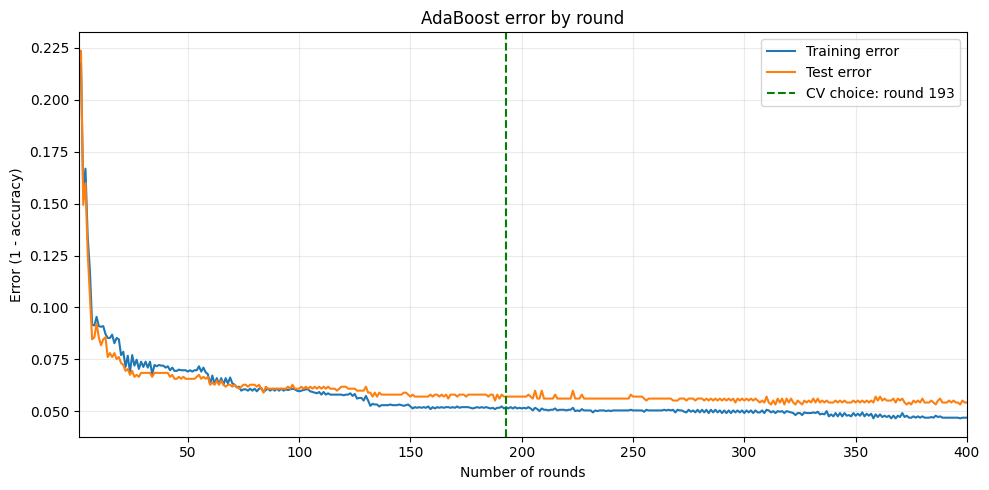

In [31]:
fold_round_scores = []
for fit_indices, validation_indices in cv.split(X_train, y_train):
    fold_ada = clone(ada).fit(X_train[fit_indices], y_train[fit_indices])
    scores_by_round = list(fold_ada.staged_score(
        X_train[validation_indices], y_train[validation_indices]
    ))
    fold_round_scores.append(scores_by_round)

fold_round_scores = np.array(fold_round_scores)
mean_round_accuracy = fold_round_scores.mean(axis=0)
chosen_round = int(np.argmax(mean_round_accuracy) + 1)

chosen_test_error = ada_test_errors[chosen_round - 1]
best_test_round = int(np.argmin(ada_test_errors) + 1)
best_test_error = ada_test_errors[best_test_round - 1]
chosen_test_accuracy = 1 - chosen_test_error
chosen_test_se = np.sqrt(chosen_test_accuracy * (1 - chosen_test_accuracy) / len(y_test))
test_error_gap = abs(chosen_test_error - best_test_error)

print("Round chosen by training CV:", chosen_round)
print(f"Mean CV accuracy at this round: {mean_round_accuracy[chosen_round - 1]:.6f}")
print(f"Test error at the chosen round: {chosen_test_error:.6f}")
print("First round with the lowest test error:", best_test_round)
print(f"Lowest test error:              {best_test_error:.6f}")
print(f"Difference in test errors:      {test_error_gap:.6f}")
print(f"Test accuracy standard error:   {chosen_test_se:.6f}")
print("Difference exceeds one standard error:", test_error_gap > chosen_test_se)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(rounds, ada_train_errors, label="Training error")
ax.plot(rounds, ada_test_errors, label="Test error")
ax.axvline(chosen_round, color="green", linestyle="--", label=f"CV choice: round {chosen_round}")
ax.set_title("AdaBoost error by round")
ax.set_xlabel("Number of rounds")
ax.set_ylabel("Error (1 - accuracy)")
ax.set_xlim(1, len(rounds))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


### 5. Label noise

I flip 20% of the training labels in five draws, with seeds SEED + 0 through SEED + 4.
Within a draw, all three models receive the same noisy labels.
The models keep random_state=SEED, and the test labels stay clean.
This experiment uses a separate AdaBoost with 200 rounds.


In [32]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx


In [33]:
ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}
clean_accuracies = {}
noisy_accuracies = {name: [] for name in noise_models}
noisy_label_draws = []
flipped_index_draws = []
noisy_ada_models = []

for name, model in noise_models.items():
    clean_model = clone(model).fit(X_train, y_train)
    clean_accuracies[name] = clean_model.score(X_test, y_test)

for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)
    noisy_label_draws.append(y_noisy)
    flipped_index_draws.append(idx)
    for name, model in noise_models.items():
        noisy_model = clone(model).fit(X_train, y_noisy)
        noisy_accuracies[name].append(noisy_model.score(X_test, y_test))
        if name == "ada200":
            noisy_ada_models.append(noisy_model)

noise_losses = {}
noise_summary_rows = []
for name in noise_models:
    accuracies = np.array(noisy_accuracies[name])
    losses = clean_accuracies[name] - accuracies
    noise_losses[name] = losses
    noise_summary_rows.append([
        name, clean_accuracies[name], accuracies.mean(), accuracies.std(), losses.mean(), losses.std()
    ])

noise_summary = pd.DataFrame(noise_summary_rows, columns=[
    "Model", "Clean accuracy", "Noisy accuracy mean", "Noisy accuracy std", "Loss mean", "Loss std"
]).set_index("Model")
display(noise_summary.round(6))

print("Accuracy loss in each draw: clean accuracy - noisy accuracy")
noise_loss_table = pd.DataFrame(noise_losses, index=[f"Draw {r}" for r in range(5)]).T
noise_loss_table.index.name = "Model"
display(noise_loss_table.round(6))


,Clean accuracy,Noisy accuracy mean,Noisy accuracy std,Loss mean,Loss std
Model,,,,,
tree,0.897241,0.731113,0.010975,0.166127,0.010975
rf,0.957184,0.901808,0.003580,0.055376,0.003580
ada200,0.942912,0.923501,0.003161,0.019410,0.003161


Accuracy loss in each draw: clean accuracy - noisy accuracy


,Draw 0,Draw 1,Draw 2,Draw 3,Draw 4
Model,,,,,
tree,0.169363,0.161751,0.185538,0.160799,0.153187
rf,0.060894,0.058040,0.052331,0.054234,0.051380
ada200,0.023787,0.019981,0.014272,0.018078,0.020932


### 6. Final weight on flipped rows

For each noisy AdaBoost, I start again with equal row weights.
I replay every fitted stump with adaboost_step and add up the final weights on the flipped rows.


In [34]:
weight_share_rows = []
for r in range(5):
    weights = np.full(len(y_train), 1 / len(y_train))
    y_noisy = noisy_label_draws[r]
    idx = flipped_index_draws[r]
    for stump in noisy_ada_models[r].estimators_:
        _, weights = adaboost_step(y_noisy, stump.predict(X_train), weights)
    assert np.isclose(weights.sum(), 1)
    weight_share_rows.append([
        r, len(idx) / len(y_train), weights[idx].sum(), len(noisy_ada_models[r].estimators_)
    ])

weight_share_table = pd.DataFrame(weight_share_rows, columns=[
    "Draw", "Initial share", "Final share", "Fitted stumps"
]).set_index("Draw")
display(weight_share_table.round(6))
final_weight_shares = weight_share_table["Final share"].to_numpy()
print(f"Final weight share mean: {final_weight_shares.mean():.6f}")
print(f"Final weight share std:  {final_weight_shares.std():.6f}")


,Initial share,Final share,Fitted stumps
Draw,,,
0,0.200127,0.391130,200
1,0.200127,0.386135,200
2,0.200127,0.396738,200
3,0.200127,0.399627,200
4,0.200127,0.396355,200


Final weight share mean: 0.393997
Final weight share std:  0.004792


### Comparing the losses

A positive difference means the first model lost more accuracy.
I pair losses from the same draw and use the same spread rule as before.


In [35]:
noise_difference_rows = []
noise_paired_differences = {}
for first, second in [("tree", "rf"), ("tree", "ada200"), ("ada200", "rf")]:
    name = f"{first} - {second}"
    differences = noise_losses[first] - noise_losses[second]
    noise_paired_differences[name] = differences
    noise_difference_rows.append([
        name, *differences, differences.mean(), differences.std(),
        abs(differences.mean()) <= differences.std(),
    ])

noise_difference_columns = ["Comparison", "Draw 0", "Draw 1", "Draw 2", "Draw 3", "Draw 4",
                            "Mean", "Std", "Inside draw spread"]
noise_difference_table = pd.DataFrame(
    noise_difference_rows, columns=noise_difference_columns
).set_index("Comparison")
noise_difference_table.round(6)


,Draw 0,Draw 1,Draw 2,Draw 3,Draw 4,Mean,Std,Inside draw spread
Comparison,,,,,,,,
tree - rf,0.108468,0.103711,0.133206,0.106565,0.101808,0.110752,0.011459,False
tree - ada200,0.145576,0.141770,0.171265,0.142721,0.132255,0.146717,0.013065,False
ada200 - rf,-0.037108,-0.038059,-0.038059,-0.036156,-0.030447,-0.035966,0.002848,False


### What the results show

The three-round example gives errors of 0.300000, 0.214286 and 0.181818, with alphas 0.847298, 1.299283 and 1.504077. These agree with the exact three-stump calculation checked above. Round 1 also matches the lecture values given in the task: about 0.071 on correct rows and 0.167 on wrong rows. The first five sklearn rounds match my updates too: the largest alpha difference is about 4.44e-16 and the largest error difference is about 5.55e-17. These small gaps come from floating-point rounding.

Training CV chooses round 193. Its test error is 0.057088, while the first minimum on the test curve is at round 312 with error 0.053283. The gap is 0.003806, smaller than the test standard error of 0.007157. The test curve reaches its best point later, but this difference does not exceed one standard error. I keep round 193 because it was chosen from the training folds.

The tree loses the most accuracy under label noise: 0.166127 on average, or 16.61 percentage points. The forest loses 0.055376, and AdaBoost with 200 rounds loses 0.019410. The tree's extra loss over the forest is 0.110752 with a paired standard deviation of 0.011459. Its extra loss over AdaBoost is 0.146717 with a standard deviation of 0.013065. The forest loses 0.035966 more than AdaBoost, with a paired standard deviation of 0.002848. All three gaps are outside the draw spread, so the ordering of the losses is clear in these five draws.

A full tree can fit individual wrong labels, which helps explain its large drop from 0.897241 to 0.731113 mean test accuracy. Averaging trees reduces this problem in the forest. AdaBoost puts more weight on the flipped rows: their share rises from 0.200127 to a mean of 0.393997, with a standard deviation of 0.004792. It is paying extra attention to these difficult rows, but still loses the least accuracy here. I think the shallow stumps and the fixed 200 rounds help it avoid fitting individual wrong labels as closely as full trees. This result is for these models and draws, not a claim that AdaBoost always handles label noise best.
